# Корпус, язык и подготовка текстовых данных

Текст рассматривается как источник признаков с собственными единицами наблюдения и правилами сохранения смысла. Основной исходник `course/data/reviews.txt` используется без изменения. Для размеченной задачи маршрутизации создаётся отдельный синтетический набор обращений.

Подготовка текста является частью постановки. Приведение регистра, удаление чисел или служебных слов могут помочь одной задаче и испортить другую. Результаты всех ячеек сохранены; примеры показывают как полезные преобразования, так и их ограничения.

## 1. Документ и свойства исходного корпуса

Документ — одна выбранная единица текста; корпус — совокупность документов. Здесь одна строка исходного TXT принимается за документ по договору формата. Изменение границ документов меняет частоты и будущие признаки.

**Среда и поиск исходника**

Библиотеки стандартной обработки текста не требуют скачивания языковых моделей. Морфологические инструменты ниже используются только при наличии локальных пакетов; основная подготовка и остальные ноутбуки от них не зависят.

In [1]:
# Шаг М3.01.01 — Среда и поиск исходника
from pathlib import Path
from collections import Counter
import re
import html
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
try:
    from nltk.stem.snowball import RussianStemmer
except ImportError:
    RussianStemmer = None
try:
    import pymorphy3
except ImportError:
    pymorphy3 = None

MODULE_DIR=Path.cwd()
COURSE_DATA=next((p/'data' for p in (MODULE_DIR,*MODULE_DIR.parents)
                  if (p/'data'/'reviews.txt').is_file()),None)
if COURSE_DATA is None:
    raise FileNotFoundError('Нужен course/data/reviews.txt')
DATASET_PATH=MODULE_DIR/'data'/'support_messages.csv'
raw_lines=(COURSE_DATA/'reviews.txt').read_text(encoding='utf-8').splitlines()
display(pd.Series({'Исходник':str(COURSE_DATA/'reviews.txt'),'Документов':len(raw_lines),
                   'Snowball локально':RussianStemmer is not None,
                   'pymorphy3 локально':pymorphy3 is not None}).to_frame('Контекст'))

,Контекст
Исходник,C:\Users\user\Downloads\BigData_Kit\course\dat...
Документов,50000
Snowball локально,True
pymorphy3 локально,True


**Чтение примеров до автоматических выводов**

Фактические строки состоят из сочетаний небольшого набора слов. В них нет отдельной метки темы, эмоции или оценки. Столбцы со смысловыми метками нельзя достроить из названия файла.

В файле TXT нет отдельной схемы полей, поэтому граница документа является договором чтения. В данном наборе одна строка соответствует одной записи. Если бы строка была только переносом оформления многострочного письма, то такое чтение раздробило бы одно наблюдение. Перед переносом приёма на другой источник требуется проверить его формат.

Отсутствие меток ограничивает допустимые задачи. Частоты и сходство можно исследовать без правильных тем, а обучение классификатора требует разметки с известным происхождением. Автоматически назначить классы по тому же слову, которое позднее станет признаком, означает получить другую, искусственно упрощённую задачу.

In [2]:
# Шаг М3.01.02 — Чтение примеров до автоматических выводов
corpus=pd.Series(raw_lines,name='text')
display(corpus.head(8).to_frame())
print('Пустых строк:',int(corpus.str.strip().eq('').sum()))
print('Полных повторов сверх первого:',int(corpus.duplicated().sum()))

,text
0,Данные задача задача задача сервер таблица узе...
1,Заказ данные поиск лог файл хранилище сумма зн...
2,Лог отчёт таблица кластер лог блок.
3,Заказ данные таблица данные кластер сумма клас...
4,Узел значение блок блок лог ключ товар товар с...
5,Таблица блок данные задача хранилище заказ таб...
6,Блок лог значение отчёт поиск ключ лог клиент ...
7,Задача ключ задача заказ.


Пустых строк: 0
Полных повторов сверх первого: 77


**Длина документа и единицы подсчёта**

Число символов, число разделённых пробелами фрагментов и число языковых токенов не обязаны совпадать. На этом этапе длина по пробелам является только быстрой диагностикой.

,Символов,Фрагментов по пробелам
count,50000.00,50000.00
mean,58.38,8.98
std,21.02,3.17
min,17.00,4.00
25%,40.00,6.00
50%,58.00,9.00
75%,76.00,12.00
max,111.00,14.00


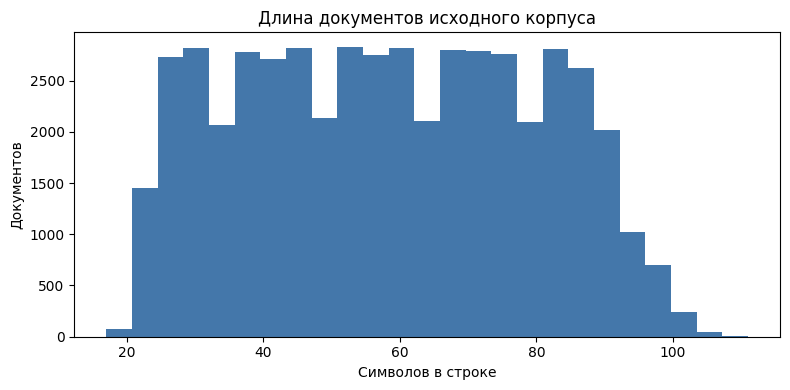

In [3]:
# Шаг М3.01.03 — Длина документа и единицы подсчёта
lengths=pd.DataFrame({'Символов':corpus.str.len(),
                       'Фрагментов по пробелам':corpus.str.split().str.len()})
display(lengths.describe().round(2))
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(lengths['Символов'],bins=25,color='#4477aa')
ax.set(xlabel='Символов в строке',ylabel='Документов',title='Длина документов исходного корпуса')
fig.tight_layout()
plt.show()
plt.close(fig)

**Контролируемые дефекты без изменения файла**

Дополнительный небольшой фрагмент показывает пустой текст, пробелы и повтор. Он хранится отдельно от исходного корпуса. Отсутствующее значение отличается от пустой строки и от строки, содержащей только пробелы.

In [4]:
# Шаг М3.01.04 — Контролируемые дефекты без изменения файла
quality_example=pd.Series(['Нужна доставка',None,'','   ','Нужна доставка','Нужна доставка'])
display(pd.DataFrame({'Исходное':quality_example,
                      'Нет значения':quality_example.isna(),
                      'Пусто после strip':quality_example.fillna('').str.strip().eq(''),
                      'Точный повтор':quality_example.duplicated(keep=False)}))
assert len(corpus)==50_000

,Исходное,Нет значения,Пусто после strip,Точный повтор
0,Нужна доставка,False,False,True
1,None,True,True,False
2,,False,True,False
3,,False,True,False
4,Нужна доставка,False,False,True
5,Нужна доставка,False,False,False


Единица наблюдения и свойства источника проверены. Название файла не заменяет разметку, а одинаковая запись не доказывает одинаковое событие.

## 2. Нормализация символов и выделение токенов

Нормализация задаёт техническую форму текста. Токенизация выделяет элементы, с которыми будет работать представление. Обе процедуры зависят от задачи и языка.

**Unicode и формы нормализации**

Один видимый символ может состоять из одного кодового пункта или из буквы с комбинируемым знаком. NFC объединяет канонически эквивалентные записи; NFKC дополнительно преобразует совместимые варианты, например полноширинные цифры.

Кодовый пункт Unicode и байтовое представление UTF-8 относятся к разным уровням. Кодировка уже задаёт перевод байтов в символы, а нормализация работает с прочитанными символами. Поэтому смена формы NFC/NFKC не является исправлением ошибочно выбранной кодировки.

Совместимая нормализация может объединять визуальные варианты ширины и пробелов. Для технических обозначений, паролей или точного воспроизведения оригинала допустимость такого объединения проверяется отдельно. В этой практике исходная строка сохраняется, а результат нормализации служит отдельным входом модели.

In [5]:
# Шаг М3.01.05 — Unicode и формы нормализации
unicode_examples=['ё','ё','Заказ получен','Заказ １２３']
display(pd.DataFrame({'Запись':unicode_examples,
                      'Кодовые пункты':[' '.join(f'U+{ord(ch):04X}' for ch in s) for s in unicode_examples],
                      'NFC':[unicodedata.normalize('NFC',s) for s in unicode_examples],
                      'NFKC':[unicodedata.normalize('NFKC',s) for s in unicode_examples]}))
print('Первоначально равны:',unicode_examples[0]==unicode_examples[1])
print('После NFC равны:',unicodedata.normalize('NFC',unicode_examples[0])==unicodedata.normalize('NFC',unicode_examples[1]))

,Запись,Кодовые пункты,NFC,NFKC
0,ё,U+0451,ё,ё
1,ё,U+0435 U+0308,ё,ё
2,Заказ получен,U+0417 U+0430 U+043A U+0430 U+0437 U+00A0 U+04...,Заказ получен,Заказ получен
3,Заказ １２３,U+0417 U+0430 U+043A U+0430 U+0437 U+0020 U+FF...,Заказ １２３,Заказ 123


Первоначально равны: False
После NFC равны: True


**Известная разметка и HTML-сущности**

HTML-сущность `&amp;` кодирует амперсанд. Её декодирование отличается от удаления тегов. Простой шаблон ниже применяется только к известной учебной разметке и не является полноценным обработчиком произвольных HTML-страниц.

In [6]:
# Шаг М3.01.06 — Известная разметка и HTML-сущности
markup_examples=['<p>Где <b>заказ</b>?</p>','Оплата&nbsp;и&nbsp;чек','Размер A &amp; B']
markup_rows=[]
for text in markup_examples:
    decoded=html.unescape(text)
    without_tags=re.sub(r'<[^>]+>',' ',decoded)
    markup_rows.append({'Исходное':text,'После сущностей':decoded,'После тегов':' '.join(without_tags.split())})
display(pd.DataFrame(markup_rows))

,Исходное,После сущностей,После тегов
0,<p>Где <b>заказ</b>?</p>,<p>Где <b>заказ</b>?</p>,Где заказ ?
1,Оплата&nbsp;и&nbsp;чек,Оплата и чек,Оплата и чек
2,Размер A &amp; B,Размер A & B,Размер A & B


**Регистр и сохранение буквы ё**

Приведение регистра сокращает технические варианты слов. Замена ё на е является отдельным решением, которое способно объединить разные слова. Выбранная нормализация сохраняет ё.

In [7]:
# Шаг М3.01.07 — Регистр и сохранение буквы ё
case_examples=['ДОСТАВКА','Доставка','доставка','всё','все','МИР','мир']
display(pd.DataFrame({'Исходное':case_examples,'casefold':[s.casefold() for s in case_examples],
                      'Если заменить ё':[s.casefold().replace('ё','е') for s in case_examples]}))

,Исходное,casefold,Если заменить ё
0,ДОСТАВКА,доставка,доставка
1,Доставка,доставка,доставка
2,доставка,доставка,доставка
3,всё,всё,все
4,все,все,все
5,МИР,мир,мир
6,мир,мир,мир


**Токенизация и границы слов**

Токен — элемент выбранного разбиения, а не обязательно словарное слово. Границы по пробелам, последовательности букв и буквенно-цифровые токены дают разные результаты. Правило должно учитывать нужные числа и составные обозначения.

Правило токенизации должно быть одинаковым при обучении и применении. Если словарь обучен на словах с дефисами, а новый текст разбивается по другому правилу, совпадение видимых формулировок не гарантирует совпадение координат.

Числа и буквенно-цифровые обозначения могут нести смысл. Для маршрутизации случайный номер заказа исключается, но для поиска размера или модели изделия он может быть главным условием. Поэтому «удалить всё, кроме букв» не является общим рецептом подготовки текстовых данных.

In [8]:
# Шаг М3.01.08 — Токенизация и границы слов
token_examples=['Не привезли заказ №123.','интернет-магазин и Wi-Fi','размер42, модель X5','Я жду чек!']
token_rows=[]
for text in token_examples:
    token_rows.append({'Текст':text,'По пробелам':text.split(),
                       'Буквы и цифры':re.findall(r'(?u)\b\w+\b',text.casefold()),
                       'Только буквы':re.findall(r'(?u)\b[^\W\d_]+\b',text.casefold())})
display(pd.DataFrame(token_rows))

,Текст,По пробелам,Буквы и цифры,Только буквы
0,Не привезли заказ №123.,"[Не, привезли, заказ, №123.]","[не, привезли, заказ, 123]","[не, привезли, заказ]"
1,интернет-магазин и Wi-Fi,"[интернет-магазин, и, Wi-Fi]","[интернет, магазин, и, wi, fi]","[интернет, магазин, и, wi, fi]"
2,"размер42, модель X5","[размер42,, модель, X5]","[размер42, модель, x5]",[модель]
3,Я жду чек!,"[Я, жду, чек!]","[я, жду, чек]","[я, жду, чек]"


**Токены словарь и частоты**

Количество токенов учитывает все появления, размер словаря — различные токены. `Counter` связывает элемент с числом его появлений. Регистр и пунктуация существенно меняют наблюдаемый размер словаря исходника.

In [9]:
# Шаг М3.01.09 — Токены словарь и частоты
space_counts=Counter(word for text in raw_lines for word in text.split())
word_counts=Counter(word for text in raw_lines for word in re.findall(r'(?u)\b\w+\b',text.casefold()))
display(pd.Series({'Фрагментов по пробелам разных':len(space_counts),
                   'Нормализованных слов разных':len(word_counts),
                   'Всего словоупотреблений':sum(word_counts.values())}).to_frame('Корпус'))
display(pd.DataFrame(word_counts.most_common(10),columns=['Токен','Частота']))

,Корпус
Фрагментов по пробелам разных,60
Нормализованных слов разных,20
Всего словоупотреблений,449221


,Токен,Частота
0,узел,22681
1,товар,22677
2,поиск,22667
3,сумма,22606
4,город,22532
5,запрос,22522
6,заказ,22508
7,сервер,22493
8,кластер,22474
9,блок,22466


**Почему предложение не равно документу**

Наивное разделение по точкам и восклицательным знакам не учитывает сокращения и десятичные записи. Граница предложения и граница записи источника решают разные задачи.

In [10]:
# Шаг М3.01.10 — Почему предложение не равно документу
sentence_examples=['Заказ №123. Нужен чек.','Адрес: ул. Лесная, д. 5. Жду курьера.','Версия 3.5 не работает!']
display(pd.DataFrame({'Документ':sentence_examples,
                      'Наивные фрагменты':[[s.strip() for s in re.split(r'[.!?]+',text) if s.strip()] for text in sentence_examples]}))

,Документ,Наивные фрагменты
0,Заказ №123. Нужен чек.,"[Заказ №123, Нужен чек]"
1,"Адрес: ул. Лесная, д. 5. Жду курьера.","[Адрес: ул, Лесная, д, 5, Жду курьера]"
2,Версия 3.5 не работает!,"[Версия 3, 5 не работает]"


Технические формы приведены к выбранным правилам, а различие символа, токена и документа сохранено. Нормализация не приравнивается к пониманию смысла.

## 3. Служебные слова и формы русского языка

Удаление частых слов и сведение словоформ уменьшают словарь, но могут терять отрицание, форму или контекст. Морфологическая обработка не равна распознаванию смысла предложения.

**Стоп-слова и отрицание**

Стоп-слова задаются выбранным списком. Отрицания не, нет и без могут определять смысл запроса, поэтому их нельзя автоматически считать шумом. Список ниже служит только демонстрацией.

In [11]:
# Шаг М3.01.11 — Стоп-слова и отрицание
safe_stop={'и','в','на','по','с','для','о','это'}
sentences=['Товар понравился','Товар не понравился','Нет чека об оплате','Без доставки заказ не нужен']
stop_rows=[]
for text in sentences:
    tokens=re.findall(r'(?u)\b\w+\b',text.casefold())
    stop_rows.append({'Фраза':text,'Выбранный список':[t for t in tokens if t not in safe_stop],
                      'Если удалить отрицания':[t for t in tokens if t not in safe_stop|{'не','нет','без'}]})
display(pd.DataFrame(stop_rows))

,Фраза,Выбранный список,Если удалить отрицания
0,Товар понравился,"[товар, понравился]","[товар, понравился]"
1,Товар не понравился,"[товар, не, понравился]","[товар, понравился]"
2,Нет чека об оплате,"[нет, чека, об, оплате]","[чека, об, оплате]"
3,Без доставки заказ не нужен,"[без, доставки, заказ, не, нужен]","[доставки, заказ, нужен]"


**Порядок слов несёт дополнительную информацию**

Одинаковые частоты слов не гарантируют одинаковую фразу. Будущая модель мешка слов потеряет порядок; представления последовательностей разберутся во втором ноутбуке.

Потеря порядка является свойством конкретного будущего представления. Проверка двух фраз с одинаковыми счётчиками показывает ограничение до обучения алгоритма. Никакой выбор классификатора не восстановит различие, если ему передали совершенно одинаковые входные векторы.

Отдельное присутствие слова «не» полезно, но не полностью решает отрицание. Область его действия определяется сочетанием слов. Поэтому сохранение отрицания и добавление последовательностей являются разными решениями. Их влияние оценивается вместе с конечной задачей на новых формулировках.

In [12]:
# Шаг М3.01.12 — Порядок слов несёт дополнительную информацию
order_pair=['Не товар нужен, а возврат','Товар нужен, а не возврат']
order_tokens=[re.findall(r'(?u)\b\w+\b',text.casefold()) for text in order_pair]
display(pd.DataFrame({'Текст':order_pair,'Частоты':[dict(Counter(tokens)) for tokens in order_tokens]}))
print('Частоты совпадают:',Counter(order_tokens[0])==Counter(order_tokens[1]))

,Текст,Частоты
0,"Не товар нужен, а возврат","{'не': 1, 'товар': 1, 'нужен': 1, 'а': 1, 'воз..."
1,"Товар нужен, а не возврат","{'товар': 1, 'нужен': 1, 'а': 1, 'не': 1, 'воз..."


Частоты совпадают: True


**Стемминг как работа с формой окончания**

Стемминг отсекает части слов по алгоритмическим правилам. Результат не обязан быть настоящим словом. Локальный Snowball не загружает словари или корпуса из сети.

In [13]:
# Шаг М3.01.13 — Стемминг как работа с формой окончания
forms=['доставка','доставки','доставкой','доставить','заказ','заказы','возвращение','возврат']
if RussianStemmer is not None:
    stemmer=RussianStemmer()
    stems=[stemmer.stem(word) for word in forms]
else:
    stems=['Локальная библиотека не установлена']*len(forms)
display(pd.DataFrame({'Словоформа':forms,'Snowball':stems}))

,Словоформа,Snowball
0,доставка,доставк
1,доставки,доставк
2,доставкой,доставк
3,доставить,достав
4,заказ,заказ
5,заказы,заказ
6,возвращение,возвращен
7,возврат,возврат


**Лемматизация с установленным словарём**

Лемма — словарная начальная форма. Морфологический анализ использует сведения о словоформах, но отдельное слово может иметь несколько разборов. Локальный словарь необязателен для остальных материалов.

Морфологические признаки описывают часть речи, число, падеж, время и другие грамматические свойства. В выводе NOUN означает существительное, VERB личную форму глагола, INFN инфинитив. Эти обозначения относятся к разбору слова и не являются метками темы обращения.

Сведение к лемме может уменьшить число вариантов словаря, но также потерять форму, полезную для задачи. Качество морфологии отдельно и качество маршрутизации всего сообщения не обязаны изменяться одинаково. Дополнительный инструмент не включается в основной Pipeline только потому, что он сложнее простого правила.

In [14]:
# Шаг М3.01.14 — Лемматизация с установленным словарём
morph=None
morph_status='Пакет не установлен; основная обработка от него не зависит'
if pymorphy3 is not None:
    try:
        morph=pymorphy3.MorphAnalyzer()
        morph_status='Локальный словарь доступен'
    except (ImportError,OSError,ValueError) as error:
        morph_status='Локальный словарь недоступен: '+str(error)
lemmas=[morph.parse(word)[0].normal_form for word in forms] if morph is not None else ['Словарь недоступен']*len(forms)
print(morph_status)
display(pd.DataFrame({'Словоформа':forms,'Лемма первого разбора':lemmas}))

Локальный словарь доступен


,Словоформа,Лемма первого разбора
0,доставка,доставка
1,доставки,доставка
2,доставкой,доставка
3,доставить,доставить
4,заказ,заказ
5,заказы,заказ
6,возвращение,возвращение
7,возврат,возврат


**Неоднозначность отдельной словоформы**

Форма «стали» может относиться к существительному и глаголу. Оценка разбора словаря не является калиброванной уверенностью в смысле целого обращения.

In [15]:
# Шаг М3.01.15 — Неоднозначность отдельной словоформы
if morph is not None:
    analyses=morph.parse('стали')[:5]
    display(pd.DataFrame([{'Лемма':p.normal_form,'Морфологические признаки':str(p.tag),
                           'Оценка словарного разбора':p.score} for p in analyses]))
else:
    display(pd.DataFrame({'Фраза':['Деталь из стали','Заказы стали приходить'],
                          'Контекстная лемма':['сталь','стать']}))

,Лемма,Морфологические признаки,Оценка словарного разбора
0,стать,"VERB,perf,intr plur,past,indc",0.975342
1,сталь,"NOUN,inan,femn sing,gent",0.010958
2,сталь,"NOUN,inan,femn plur,nomn",0.005479
3,сталь,"NOUN,inan,femn sing,datv",0.002739
4,сталь,"NOUN,inan,femn sing,loct",0.002739


Служебные слова и морфология рассмотрены как варианты представления с потерями. Никакая дополнительная языковая обработка не объявлена обязательным улучшением.

## 4. Единое правило и сохранение нужной информации

Основная нормализация использует NFKC, известную разметку, приведение регистра, замену цифровых последовательностей и пробелы. Стемминг, лемматизация и удаление стоп-слов в неё не входят.

**Функция нормализации для модуля**

Цифры заменяются словом номер в рамках учебной задачи темы обращения. Для задачи точного поиска модели товара или суммы платежа такое правило могло бы быть непригодным. Возвращается новая строка; исходный столбец не переписывается.

Нормализация выполняется до выделения числовых признаков и не обучается по частотам. При этом разные правила нормализации всё равно являются вариантами проектирования, которые нельзя многократно менять по окончательному тесту. В основном эксперименте выбранное правило зафиксировано заранее.

На вход функции должен поступать проверенный текст. Пропуск необходимо обработать до приведения через str, иначе получится буквальный текст None или nan. В исходной размеченной таблице заполненность проверяется отдельно; при применении классификатора предусматривается проверка типа и пустоты запроса.

In [16]:
# Шаг М3.01.16 — Функция нормализации для модуля
def normalize_text(text):
    text=unicodedata.normalize('NFKC',html.unescape(str(text)))
    text=re.sub(r'<[^>]+>',' ',text)
    text=re.sub(r'\d+',' номер ',text)
    return ' '.join(text.casefold().split())

normalization_examples=['<p>ГДЕ ЗАКАЗ №123?</p>','Платёж &amp; чек №456','Всё ещё нет доставки']
display(pd.DataFrame({'Исходное':normalization_examples,
                      'Для модели':[normalize_text(s) for s in normalization_examples]}))

,Исходное,Для модели
0,<p>ГДЕ ЗАКАЗ №123?</p>,где заказ no номер ?
1,Платёж &amp; чек №456,платёж & чек no номер
2,Всё ещё нет доставки,всё ещё нет доставки


**Потери на минимальных парах**

Нормализация может объединить разные исходные строки. Проверка минимальных пар показывает, какие различия сохранены и какие потеряны. Это свойство функции, а не качество обученной модели.

In [17]:
# Шаг М3.01.17 — Потери на минимальных парах
minimal_pairs=[('Модель 42 нужна','Модель 43 нужна'),
                ('Товар нужен','Товар не нужен'),('всё получено','все получено')]
display(pd.DataFrame([{'Первая':a,'Вторая':b,'После первой':normalize_text(a),
                       'После второй':normalize_text(b),'Совпали':normalize_text(a)==normalize_text(b)}
                      for a,b in minimal_pairs]))

,Первая,Вторая,После первой,После второй,Совпали
0,Модель 42 нужна,Модель 43 нужна,модель номер нужна,модель номер нужна,True
1,Товар нужен,Товар не нужен,товар нужен,товар не нужен,False
2,всё получено,все получено,всё получено,все получено,False


**Извлечение служебного номера отдельно**

Информацию можно отделить от текста модели и сохранить в метаданных. Номер помогает связать ответ с обращением, но не становится обучающим признаком темы.

In [18]:
# Шаг М3.01.18 — Извлечение служебного номера отдельно
number_examples=pd.Series(['Заказ №12345: нужна доставка','Заказ №77881: нужен чек','Нужна инструкция'])
number_metadata=number_examples.str.extract(r'№\s*(?P<order_number>\d+)')
display(pd.concat([number_examples.rename('Исходное'),number_metadata,
                    number_examples.map(normalize_text).rename('Текст модели')],axis=1))

,Исходное,order_number,Текст модели
0,Заказ №12345: нужна доставка,12345,заказ no номер : нужна доставка
1,Заказ №77881: нужен чек,77881,заказ no номер : нужен чек
2,Нужна инструкция,NaN,нужна инструкция


**Частоты корпуса после выбранного правила**

Частоты подсчитываются по нормализованным словам, а не по темам. Близкие числа появлений в данном синтетическом источнике не подтверждают смысловых кластеров.

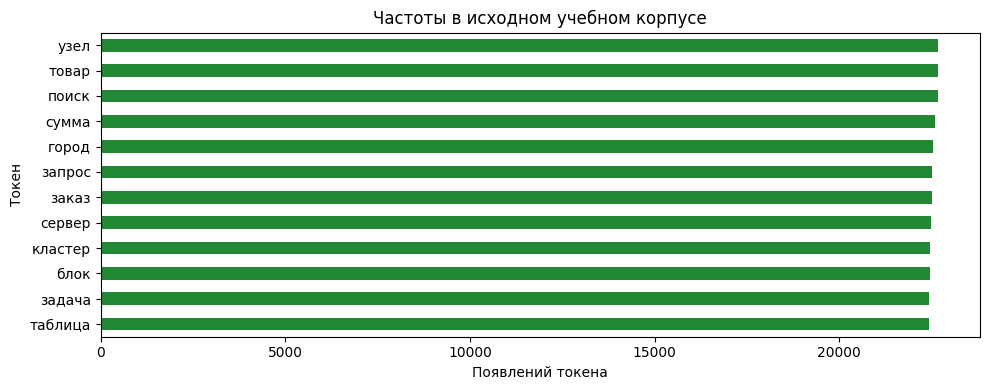

Размер нормализованного словаря: 20


In [19]:
# Шаг М3.01.19 — Частоты корпуса после выбранного правила
normalized_corpus=corpus.map(normalize_text)
normalized_counts=Counter(token for text in normalized_corpus for token in re.findall(r'(?u)\b\w+\b',text))
frequency=pd.Series(normalized_counts).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(10,4))
frequency.head(12).sort_values().plot.barh(ax=ax,color='#228833')
ax.set(xlabel='Появлений токена',ylabel='Токен',title='Частоты в исходном учебном корпусе')
fig.tight_layout()
plt.show()
plt.close(fig)
print('Размер нормализованного словаря:',len(normalized_counts))

Выбранная функция и её потери проверены. Служебные сведения сохраняются отдельно, а частоты исходника не превращаются в выдуманную разметку.

## 5. Размеченные обращения и независимость проверки

Дополнительный источник содержит синтетические обращения четырёх тем. Разделение задано по семействам формулировок до обучения. Варианты одного семейства и повторные выгрузки одного обращения не должны попадать в разные части.

**Создание дополнительного источника**

Фразы и темы заданы автором практики. У каждой темы 18 смысловых шаблонов; первые 12 семейств относятся к train, следующие 3 к validation, последние 3 к test. Вариации регистра, пробелов и служебного номера не создают независимое семейство.

In [20]:
# Шаг М3.01.20 — Создание дополнительного источника
# Формулировки и метки созданы специально для обучения, не взяты из реальных обращений.
rng = np.random.default_rng(73)
phrases = {
    'доставка': [
        'Курьер перенёс доставку, когда привезут заказ',
        'Посылка застряла на складе, где узнать срок доставки',
        'Трек отправления не меняется, прошу проверить перевозку',
        'Нужен другой адрес для курьера при доставке',
        'Заказ ещё в пути, назначенная дата уже прошла',
        'Не могу согласовать время приезда курьера',
        'В пункте выдачи пока нет моей посылки',
        'Прошу уточнить маршрут и дату получения заказа',
        'Уведомление о прибытии есть, но курьера не было',
        'Доставка задерживается второй день, где отправление',
        'Хочу перенести получение посылки на вечер',
        'Перевозчик не нашёл адрес, как исправить доставку',
        'Когда ждать посылку после передачи перевозчику',
        'Курьер не приехал в согласованный интервал',
        'Подскажите срок прибытия отправления в пункт выдачи',
        'Посылка не прибыла к обещанной дате, уточните местоположение',
        'Ожидаю курьера, но время доставки снова изменилось',
        'Где сейчас отправление и когда можно его получить'],
    'оплата': [
        'Карта списала деньги дважды при оплате заказа',
        'Платёж не проходит, банк отклоняет операцию',
        'После списания денег заказ отмечен неоплаченным',
        'Не пришёл кассовый чек после платежа',
        'Можно ли оплатить покупку другой банковской картой',
        'В счёте неправильная сумма, проверьте начисление',
        'Платёж завис, а банк уже подтвердил списание',
        'Нужна квитанция об оплате для отчёта',
        'Промокод не уменьшил сумму при расчёте',
        'Банк требует подтверждение платежа, как завершить оплату',
        'Хочу изменить способ внесения денег за заказ',
        'Списанная сумма отличается от итоговой цены в чеке',
        'Деньги с карты ушли, подтверждения оплаты нет',
        'При расчёте картой появляется ошибка платежа',
        'Где получить электронный чек за оплаченную покупку',
        'Банковская операция прошла повторно, деньги сняли ещё раз',
        'Оплата не подтверждается после успешного списания с карты',
        'Нужен документ о внесённой сумме и завершённом платеже'],
    'товар': [
        'У полученного товара сломана кнопка включения',
        'В коробке оказался другой размер, вещь не подходит',
        'Прибор не работает после первого включения',
        'В комплекте отсутствует обещанный кабель',
        'Цвет изделия отличается от описания на сайте',
        'У товара повреждён корпус и видны трещины',
        'Покупка пришла без инструкции и крепления',
        'На экране устройства появились полосы',
        'Материал вещи не соответствует заявленному составу',
        'При работе прибор сильно шумит и нагревается',
        'В упаковке недостаёт одной детали комплекта',
        'Полученная модель отличается от указанной в карточке',
        'Товар перестал включаться, нужна проверка исправности',
        'Вместо выбранного размера положили другую вещь',
        'Изделие повреждено, подскажите как проверить комплектность',
        'Кнопки устройства не реагируют, похоже на неисправность',
        'Описание обещало полный комплект, но детали отсутствуют',
        'Качество полученной вещи не соответствует описанию модели'],
    'возврат': [
        'Как оформить возврат покупки и получить деньги обратно',
        'Хочу отказаться от товара, где создать заявление на возврат',
        'Уточните срок возврата денег после передачи покупки',
        'Нужен бланк заявления для возврата заказа',
        'Где сдать покупку для возврата, товар мне не нужен',
        'Заявление на возврат принято, когда перечислят деньги',
        'Как отменить покупку и вернуть уплаченную сумму',
        'Нужна инструкция по обратной отправке товара',
        'Прошу проверить статус заявки на возврат денег',
        'Можно ли вернуть товар без бумажного заявления',
        'Отказ от покупки оформлен, но возврат суммы задерживается',
        'Как получить подтверждение приёма возвращённой покупки',
        'Хочу вернуть ненужный заказ, подскажите порядок оформления',
        'Когда придут деньги за уже возвращённый товар',
        'Куда направить заявление об отказе от покупки',
        'Подскажите процедуру возврата покупки и перечисления средств',
        'Отправил товар обратно, как узнать срок возмещения',
        'Нужно оформить отказ от заказа и возврат оплаченной суммы']
}
prefixes = ['Здравствуйте. ', 'Добрый день! ', 'Подскажите, пожалуйста: ',
            'Помогите разобраться. ', 'Вопрос по заказу: ', '']
suffixes = ['Прошу ответить в сообщении.', 'Жду уточнения.', 'Спасибо за помощь.',
            'Нужна информация по моему обращению.', '']
per_family = {'доставка':45, 'оплата':30, 'товар':26, 'возврат':20}
records = []
for topic, templates in phrases.items():
    for family_index, phrase in enumerate(templates):
        split = 'train' if family_index < 12 else ('validation' if family_index < 15 else 'test')
        family = f'{topic}_{family_index:02}'
        for variant in range(per_family[topic]):
            case_id = f'{family}_{variant:03}'
            number = int(rng.integers(10_000, 99_999))
            text = f'{rng.choice(prefixes)}{phrase}. Заказ №{number}. {rng.choice(suffixes)}'.strip()
            if variant % 9 == 0:
                text = text.upper()
            if variant % 7 == 0:
                text = text.replace(' ', '\u00a0')
            if variant % 13 == 0:
                text = '<p>' + text + '</p>'
            row = {'case_id':case_id, 'family_id':family, 'text':text, 'topic':topic, 'split':split}
            records.append(row)
            if variant % 11 == 0:
                records.append(row.copy())
messages = pd.DataFrame(records)
DATASET_PATH.parent.mkdir(parents=True, exist_ok=True)
messages.to_csv(DATASET_PATH,index=False)
display(pd.crosstab(messages['topic'],messages['split']))
print('Строк выгрузки:',len(messages),'обращений:',messages['case_id'].nunique())

split,test,train,validation
topic,,,
возврат,66,264,66
доставка,150,600,150
оплата,99,396,99
товар,87,348,87


Строк выгрузки: 2412 обращений: 2178


**Согласованность повторов до удаления**

Повторный case_id разрешено объединить только после проверки, что ему соответствуют одинаковые текст, тема и семейство. При конфликте требуется разбор, а не произвольный выбор первой строки.

Технический повтор выгрузки и одинаковое содержание разных событий различаются. Для первого случая есть совпадающий case_id и проверка согласованности всех значимых полей. Для второго одинаковые формулировки могут быть реальными независимыми обращениями, поэтому один только текст не позволяет достоверно восстановить число событий.

Дедупликация по идентификатору в данном источнике не обучает статистику и не выбирает модель. После неё сохраняется связь текста с семейством. Именно семейство используется как единица независимости проверки, потому что номера и приветствия не создают новый смысловой шаблон.

In [21]:
# Шаг М3.01.21 — Согласованность повторов до удаления
messages=pd.read_csv(DATASET_PATH)
conflicts=messages.groupby('case_id')[['text','topic','family_id','split']].nunique(dropna=False)
assert conflicts.le(1).all().all()
unique_messages=messages.drop_duplicates('case_id').copy()
assert unique_messages['text'].notna().all()
assert unique_messages['text'].str.strip().ne('').all()
display(pd.Series({'Строк экспорта':len(messages),'Уникальных обращений':len(unique_messages),
                   'Удалено полных повторных выгрузок':len(messages)-len(unique_messages)}).to_frame('Контроль'))

,Контроль
Строк экспорта,2412
Уникальных обращений,2178
Удалено полных повторных выгрузок,234


**Проверка разбиения по семействам**

Метки темы и части служат для эксперимента и не являются входным текстом классификатора. Обучение словаря в следующем ноутбуке выполняется только на train.

In [22]:
# Шаг М3.01.22 — Проверка разбиения по семействам
parts={name:unique_messages.loc[unique_messages['split'].eq(name)].copy()
       for name in ['train','validation','test']}
families={name:set(frame['family_id']) for name,frame in parts.items()}
assert families['train'].isdisjoint(families['validation'])
assert families['train'].isdisjoint(families['test'])
assert families['validation'].isdisjoint(families['test'])
display(pd.crosstab(unique_messages['topic'],unique_messages['split']))
print('Семейств по частям:',{name:len(values) for name,values in families.items()})

split,test,train,validation
topic,,,
возврат,60,240,60
доставка,135,540,135
оплата,90,360,90
товар,78,312,78


Семейств по частям: {'train': 48, 'validation': 12, 'test': 12}


**Проверка нормализованных совпадений между частями**

Непересечение идентификаторов семейства дополняется проверкой фактического текста. Сравниваются нормализованные строки.

Проверка точных совпадений дополняет данные о происхождении, но не заменяет их. Одна буква или добавленное приветствие способны сделать строки разными при почти неизменном содержании. Поэтому случайная проверка по строкам может быть слишком лёгкой даже после удаления полных копий.

Результат на новых семействах относится к разнообразию данного генератора. В реальном потоке могут появиться несколько намерений в одном сообщении, неизвестная тема, сленг или другой канал общения. Наличие честного учебного разбиения необходимо, но не доказывает покрытие всех будущих условий.

In [23]:
# Шаг М3.01.23 — Проверка нормализованных совпадений между частями
normalized_parts={name:set(frame['text'].map(normalize_text)) for name,frame in parts.items()}
intersections=pd.Series({
    'train / validation':len(normalized_parts['train'] & normalized_parts['validation']),
    'train / test':len(normalized_parts['train'] & normalized_parts['test']),
    'validation / test':len(normalized_parts['validation'] & normalized_parts['test'])})
display(intersections.to_frame('Совпадающих нормализованных текстов'))
assert intersections.eq(0).all()

,Совпадающих нормализованных текстов
train / validation,0
train / test,0
validation / test,0


**Что произойдёт при случайном делении строк**

Пример показывает пересечение семейств при случайном разбиении тех же обращений. Он не используется как основной эксперимент и не даёт численной оценки величины завышения качества.

In [24]:
# Шаг М3.01.24 — Что произойдёт при случайном делении строк
random_train,random_check=train_test_split(unique_messages,test_size=.25,
                                            stratify=unique_messages['topic'],random_state=73)
shared_families=set(random_train['family_id']) & set(random_check['family_id'])
print('Семейств одновременно с двух сторон:',len(shared_families))
print('Обращений в случайной проверке с уже виденным семейством:',
      int(random_check['family_id'].isin(shared_families).sum()))

Семейств одновременно с двух сторон: 72
Обращений в случайной проверке с уже виденным семейством: 545


**Паспорт готовности корпуса**

Подготовлена входная таблица с сохранёнными исходными текстами и известными ролями. Нормализация не обучает словарь и не заменяет последующую векторизацию.

In [25]:
# Шаг М3.01.25 — Паспорт готовности корпуса
ready_checks=pd.Series({
    'Исходных строк TXT по-прежнему 50000':len(corpus)==50_000,
    'Разметка нового корпуса имеет четыре класса':unique_messages['topic'].nunique()==4,
    'case_id после объединения уникален':unique_messages['case_id'].is_unique,
    'Пустых нормализованных обращений нет':unique_messages['text'].map(normalize_text).str.strip().ne('').all(),
    'Отрицание сохранено':'не' in normalize_text('Товар не нужен').split(),
    'Буква ё сохранена':'ё' in normalize_text('всё'),
    'Схема текста и метки раздельна':'text' in unique_messages and 'topic' in unique_messages
},name='Проверено')
display(ready_checks.to_frame())
assert ready_checks.all()

,Проверено
Исходных строк TXT по-прежнему 50000,True
Разметка нового корпуса имеет четыре класса,True
case_id после объединения уникален,True
Пустых нормализованных обращений нет,True
Отрицание сохранено,True
Буква ё сохранена,True
Схема текста и метки раздельна,True


Подготовлен источник для классификации с групповым разбиением и проверенным происхождением. Исходный TXT сохранён для отдельного изучения представлений и ограничений анализа.

## Полученный результат

Исследован исходный корпус, проверены Unicode, разметка, токены, отрицания и морфологические варианты. Определена лёгкая нормализация, создан отдельный размеченный набор и проверена независимость частей по происхождению и точным совпадениям.

В следующих файлах изучаются числовые представления, классификация и поиск с группировкой. Никакие темы или оценки исходного TXT не были выдуманы.

## Документация

[Нормализация Unicode в Python](https://docs.python.org/3/library/unicodedata.html)

[Извлечение текстовых признаков](https://scikit-learn.org/1.8/modules/feature_extraction.html#text-feature-extraction)